<a href="https://colab.research.google.com/github/flprincich/Python-Prep/blob/main/guardian_analisis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Guardián de inundación comunitario - Análisis con pandas

Este notebook descarga el historial del canal de ThingSpeak, limpia los datos, calcula estadísticas y arma los gráficos.

**Cómo usarlo en Google Colab:** subí este archivo a colab.research.google.com (Archivo > Subir cuaderno) y ejecutá las celdas en orden (Entorno de ejecución > Ejecutar todo).

Mientras no tengas la placa funcionando, dejá `USAR_DATOS_DE_PRUEBA = True`: genera una inundación simulada para que puedas probar todo el análisis.

## 1. Configuración

In [ ]:
CHANNEL_ID = "3533124"        # número de tu canal de ThingSpeak, por ejemplo "1234567"
READ_API_KEY = ""      # solo si el canal es privado (Read API Key)
RESULTADOS = 8000      # ThingSpeak entrega como máximo 8000 registros por pedido
USAR_DATOS_DE_PRUEBA = False   # cambiar a False cuando haya datos reales

UMBRALES_CM = [5, 15, 30, 60]   # aviso, alerta, peligro, evacuación recomendada
ZONA_HORARIA = "America/Argentina/Buenos_Aires"

## 2. Obtener los datos

In [ ]:
import io
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

COLUMNAS = {
    "field1": "nivel_cm",
    "field2": "agua_piso_pct",
    "field3": "velocidad_cm_min",
    "field4": "estado",
    "field5": "respuesta",
    "field6": "dist_cruda_cm",
    "field7": "baseline_cm",
    "field8": "modo_noche",
}

def descargar_thingspeak(channel_id, api_key="", results=8000):
    """Descarga el historial del canal como CSV y lo devuelve como DataFrame."""
    url = f"https://api.thingspeak.com/channels/{channel_id}/feeds.csv"
    params = {"results": results}
    if api_key:
        params["api_key"] = api_key
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text))

def generar_datos_prueba(seed=7):
    """Simula 6 horas con una tormenta: subida del agua, sensor del piso y ruido de sensor."""
    rng = np.random.default_rng(seed)
    n = 6 * 3 * 60                      # una lectura cada 20 s durante 6 horas
    t = pd.date_range("2026-11-05 21:00", periods=n, freq="20s", tz="UTC")
    x = np.arange(n)
    nivel = np.clip(70 * np.exp(-((x - 600) ** 2) / (2 * 160 ** 2)) + rng.normal(0, 0.6, n), 0, None)
    agua_piso = np.clip(np.where(nivel > 3, 70 + nivel, nivel * 15) + rng.normal(0, 4, n), 0, 100)
    vel = np.gradient(nivel) * 3                                          # cm por minuto (lecturas cada 20 s)
    estado = np.digitize(nivel, UMBRALES_CM)
    nivel[rng.choice(n, 6, replace=False)] += rng.uniform(40, 90, 6)      # lecturas falsas
    nivel[rng.choice(n, 12, replace=False)] = np.nan                      # huecos
    respuesta = np.where(estado >= 3, 1, 0)
    df = pd.DataFrame({
        "created_at": t.strftime("%Y-%m-%d %H:%M:%S UTC"),
        "entry_id": np.arange(1, n + 1),
        "field1": nivel, "field2": agua_piso.round(0), "field3": vel.round(1),
        "field4": estado, "field5": respuesta,
        "field6": (150 - nivel).round(1), "field7": 150.0, "field8": 1,
    })
    return df

if USAR_DATOS_DE_PRUEBA:
    crudo = generar_datos_prueba()
    print("Usando datos de prueba simulados")
else:
    crudo = descargar_thingspeak(CHANNEL_ID, READ_API_KEY, RESULTADOS)
    print("Descargados desde ThingSpeak")

print(crudo.shape)
crudo.head()

Descargados desde ThingSpeak
(2021, 10)


,created_at,entry_id,field1,field2,field3,field4,field5,field6,field7,field8
0,2026-10-14 15:06:48 UTC,1,0.0,1,0.0,0,0,0.0,-1.0,0
1,2026-10-14 15:07:08 UTC,2,0.0,2,0.0,0,0,0.0,-1.0,0
2,2026-10-14 15:07:28 UTC,3,0.0,3,0.0,0,0,0.0,-1.0,0
3,2026-10-14 15:07:48 UTC,4,0.0,3,0.0,0,0,0.0,-1.0,0
4,2026-10-14 15:08:08 UTC,5,0.0,2,0.0,0,0,0.0,-1.0,0


## 3. Limpieza

Pasos: renombrar columnas, convertir la fecha a hora de Argentina, pasar todo a número, sacar duplicados y valores imposibles, y detectar lecturas falsas (picos aislados) con una mediana móvil.

In [ ]:
df = crudo.rename(columns=COLUMNAS).copy()

# Fecha y hora local
df["created_at"] = pd.to_datetime(df["created_at"], utc=True).dt.tz_convert(ZONA_HORARIA)

# Todo a número (lo que no se pueda convertir queda como NaN)
cols_num = list(COLUMNAS.values())
df[cols_num] = df[cols_num].apply(pd.to_numeric, errors="coerce")

antes = len(df)
df = df.drop_duplicates(subset="created_at").sort_values("created_at").reset_index(drop=True)
print("Duplicados eliminados:", antes - len(df))

print("Nulos por columna:")
print(df[cols_num].isna().sum())

# Rangos válidos
df.loc[~df["nivel_cm"].between(0, 150), "nivel_cm"] = np.nan
df.loc[~df["agua_piso_pct"].between(0, 100), "agua_piso_pct"] = np.nan

# Lecturas falsas: pico aislado que se aleja mucho de la mediana móvil
mediana = df["nivel_cm"].rolling(5, center=True, min_periods=1).median()
df["es_atipico"] = (df["nivel_cm"] - mediana).abs() > 15
print("Valores atípicos detectados:", int(df["es_atipico"].sum()))

df["nivel_limpio"] = df["nivel_cm"].mask(df["es_atipico"])
df["nivel_limpio"] = df["nivel_limpio"].interpolate(limit=6)   # rellena huecos cortos
df = df.dropna(subset=["nivel_limpio"]).reset_index(drop=True)
df.head()

Duplicados eliminados: 0
Nulos por columna:
nivel_cm            0
agua_piso_pct       0
velocidad_cm_min    0
estado              0
respuesta           0
dist_cruda_cm       0
baseline_cm         0
modo_noche          0
dtype: int64
Valores atípicos detectados: 21


,created_at,entry_id,nivel_cm,agua_piso_pct,velocidad_cm_min,estado,respuesta,dist_cruda_cm,baseline_cm,modo_noche,es_atipico,nivel_limpio
0,2026-10-14 12:06:48-03:00,1,0.0,1.0,0.0,0,0,0.0,-1.0,0,False,0.0
1,2026-10-14 12:07:08-03:00,2,0.0,2.0,0.0,0,0,0.0,-1.0,0,False,0.0
2,2026-10-14 12:07:28-03:00,3,0.0,3.0,0.0,0,0,0.0,-1.0,0,False,0.0
3,2026-10-14 12:07:48-03:00,4,0.0,3.0,0.0,0,0,0.0,-1.0,0,False,0.0
4,2026-10-14 12:08:08-03:00,5,0.0,2.0,0.0,0,0,0.0,-1.0,0,False,0.0


## 4. Estadística descriptiva

In [ ]:
print(df[["nivel_limpio", "agua_piso_pct", "velocidad_cm_min"]].describe().round(2))

# Tiempo en cada estado (suma de los intervalos entre lecturas)
paso = df["created_at"].diff().dt.total_seconds().fillna(0).clip(upper=120)
tiempo = paso.groupby(df["estado"]).sum() / 60
nombres = {0: "Seguro", 1: "Aviso", 2: "Alerta", 3: "Peligro", 4: "Evacuación"}
tiempo.index = [nombres.get(int(i), str(i)) for i in tiempo.index]
print("\nMinutos en cada estado:")
print(tiempo.round(1))

print("\nNivel máximo:", round(df["nivel_limpio"].max(), 1), "cm a las",
      df.loc[df["nivel_limpio"].idxmax(), "created_at"].strftime("%d/%m %H:%M"))
# Concordancia entre los dos sensores: el ultrasónico marca 5 cm o más y el sensor del piso marca agua
ultra_mojado = df["nivel_limpio"] >= 5
piso_mojado = df["agua_piso_pct"] >= 50
print("Concordancia entre sensores:", round((ultra_mojado == piso_mojado).mean() * 100, 1), "% de las lecturas")

       nivel_limpio  agua_piso_pct  velocidad_cm_min
count       1997.00        1997.00           1997.00
mean           7.30           3.08              2.21
std           18.78           9.31             21.46
min            0.00           0.00           -118.20
25%            0.00           0.00              0.00
50%            0.00           0.00              0.00
75%            0.50           0.00              0.00
max          138.80          81.00            290.60

Minutos en cada estado:
Seguro        597.6
Aviso          24.9
Alerta         53.7
Peligro        63.4
Evacuación     38.6
Name: created_at, dtype: float64

Nivel máximo: 138.8 cm a las 31/10 20:55
Concordancia entre sensores: 79.1 % de las lecturas


## 5. Gráficos

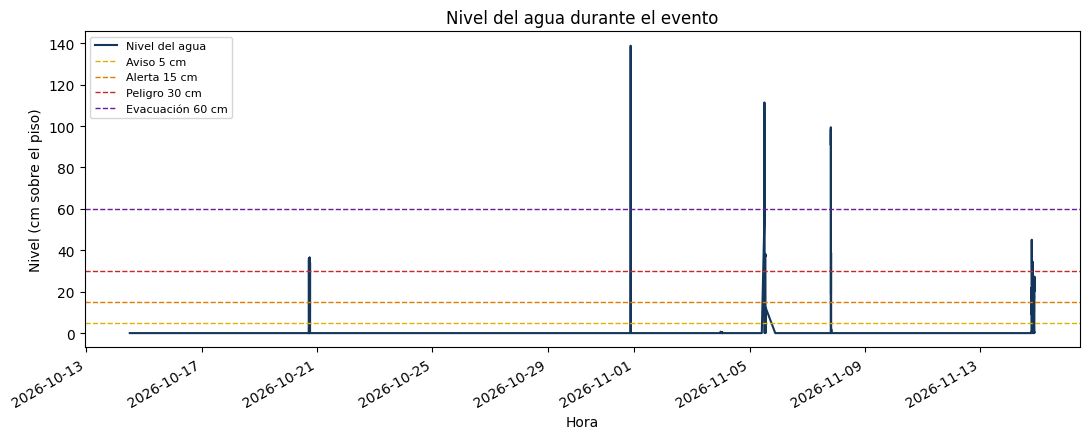

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(df["created_at"], df["nivel_limpio"], color="#14365A", lw=1.5, label="Nivel del agua")
colores = ["#E0B000", "#E07B00", "#C62828", "#6A1B9A"]
etiquetas = ["Aviso 5 cm", "Alerta 15 cm", "Peligro 30 cm", "Evacuación 60 cm"]
for u, c, e in zip(UMBRALES_CM, colores, etiquetas):
    ax.axhline(u, color=c, ls="--", lw=1, label=e)
ax.set_title("Nivel del agua durante el evento")
ax.set_ylabel("Nivel (cm sobre el piso)")
ax.set_xlabel("Hora")
ax.legend(loc="upper left", fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

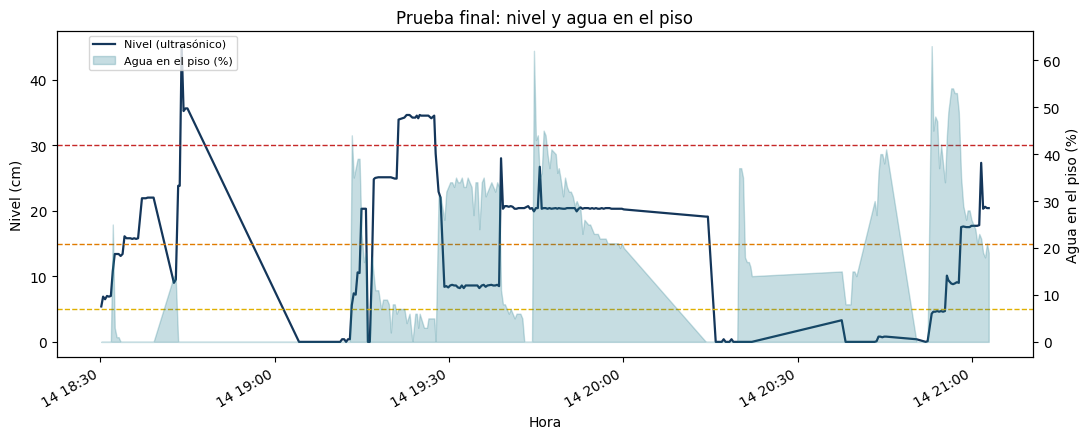

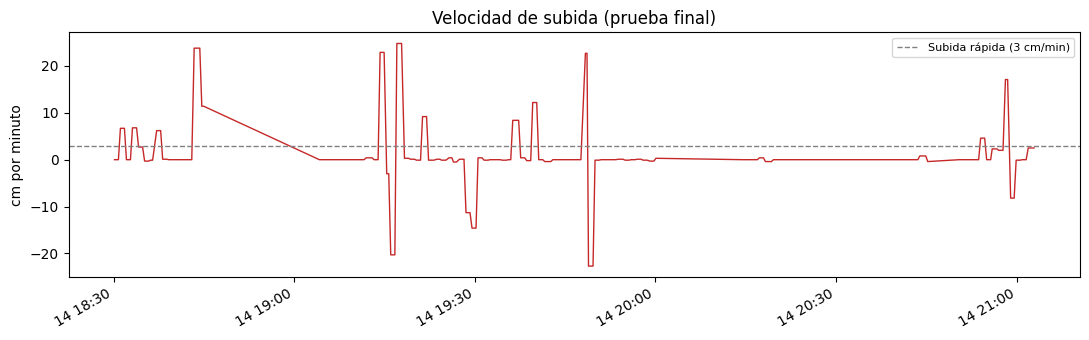

In [ ]:
# Solo la prueba final (ajustá el horario si hace falta)
t0 = pd.Timestamp("2026-11-14 18:30", tz=ZONA_HORARIA)
d = df[df["created_at"] >= t0]

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.plot(d["created_at"], d["nivel_limpio"], color="#14365A", lw=1.6, label="Nivel (ultrasónico)")
for u, c in zip(UMBRALES_CM[:3], ["#E0B000", "#E07B00", "#C62828"]):
    ax1.axhline(u, color=c, ls="--", lw=1)
ax1.set_ylabel("Nivel (cm)")
ax1.set_xlabel("Hora")

ax2 = ax1.twinx()
ax2.fill_between(d["created_at"], d["agua_piso_pct"], color="#1F7A8C", alpha=0.25, label="Agua en el piso (%)")
ax2.set_ylabel("Agua en el piso (%)")
ax1.set_title("Prueba final: nivel y agua en el piso")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92), fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# Velocidad de subida, solo la prueba final
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(d["created_at"], d["velocidad_cm_min"], color="#C62828", lw=1)
ax.axhline(3, color="grey", ls="--", lw=1, label="Subida rápida (3 cm/min)")
ax.set_title("Velocidad de subida (prueba final)")
ax.set_ylabel("cm por minuto")
ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 6. Eventos de alerta

In [ ]:
df["en_alerta"] = df["estado"] >= 1
df["evento"] = (df["en_alerta"] != df["en_alerta"].shift()).cumsum()

eventos = (df[df["en_alerta"]]
           .groupby("evento")
           .agg(inicio=("created_at", "min"), fin=("created_at", "max"),
                pico_cm=("nivel_limpio", "max"), estado_max=("estado", "max")))
eventos["duracion_min"] = ((eventos["fin"] - eventos["inicio"]).dt.total_seconds() / 60).round(1)
eventos["respondio"] = df[df["en_alerta"]].groupby("evento")["respuesta"].max().gt(0)
eventos

,inicio,fin,pico_cm,estado_max,duracion_min,respondio
evento,,,,,,
2,2026-10-20 17:08:05-03:00,2026-10-20 17:12:15-03:00,36.000000,4,4.2,False
4,2026-10-20 17:17:55-03:00,2026-10-20 17:22:35-03:00,9.700000,2,4.7,False
6,2026-10-20 17:27:15-03:00,2026-10-20 17:31:35-03:00,10.100000,2,4.3,False
8,2026-10-20 17:40:45-03:00,2026-10-20 17:45:15-03:00,36.200000,4,4.5,False
10,2026-10-20 17:47:55-03:00,2026-10-20 17:52:30-03:00,36.600000,4,4.6,False
12,2026-10-20 18:06:00-03:00,2026-10-20 18:08:30-03:00,34.100000,4,2.5,False
14,2026-10-27 21:32:14-03:00,2026-10-27 21:32:43-03:00,0.000000,4,0.5,False
16,2026-10-31 20:11:32-03:00,2026-10-31 20:12:32-03:00,0.000000,4,1.0,False
18,2026-10-31 20:50:43-03:00,2026-10-31 20:58:43-03:00,138.800000,4,8.0,False


## 7. Guardar el resultado

In [ ]:
df.to_csv("datos_limpios.csv", index=False)
eventos.to_csv("eventos.csv")
print("Archivos guardados: datos_limpios.csv y eventos.csv (están en el panel de archivos de Colab)")

Archivos guardados: datos_limpios.csv y eventos.csv (están en el panel de archivos de Colab)
